# 1. Initialize

In [1]:
import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Random Seed untuk Reproduksibilitas (Protokol 4.2)
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Konfigurasi Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


# 2. Download & Filter Dataset

In [2]:
# 1. Download dataset (split trainval bawaan)
raw_data = datasets.OxfordIIITPet(root="./data", split="trainval", target_types="category", download=True)

# 2. 5 Kucing dan 5 Anjing
selected_breeds = [
    # 5 Kucing
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair',
    # 5 Anjing
    'Beagle', 'Boxer', 'Chihuahua', 'Pug', 'Samoyed'
]

# Normalize nama kelas
def normalize_name(name):
    return name.lower().replace('_', ' ').replace('-', ' ').strip()

norm_classes = [normalize_name(c) for c in raw_data.classes]
selected_indices = [norm_classes.index(normalize_name(b)) for b in selected_breeds]

# Indexing (0 - 9)
class_names = [raw_data.classes[i] for i in selected_indices]
class_map = {orig_idx: new_idx for new_idx, orig_idx in enumerate(selected_indices)}

print("10 Kelas Terpilih (5 Kucing & 5 Anjing):")
print(class_names)

# 3. Filter Data untuk 10 kelas
filtered_indices = [i for i, target in enumerate(raw_data._labels) if target in selected_indices]
filtered_targets = [class_map[raw_data._labels[i]] for i in filtered_indices]

# 4. Stratified Split: 70% Train, 15% Val, 15% Test
train_idx, temp_idx, y_train, y_temp = train_test_split(
    filtered_indices, filtered_targets, test_size=0.30, stratify=filtered_targets, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"Jumlah sampel: \nTrain: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")

100%|██████████| 792M/792M [00:21<00:00, 37.3MB/s]
100%|██████████| 19.2M/19.2M [00:00<00:00, 20.5MB/s]


10 Kelas Terpilih (5 Kucing & 5 Anjing):
['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', 'Beagle', 'Boxer', 'Chihuahua', 'Pug', 'Samoyed']
Jumlah sampel: 
Train: 697, Val: 149, Test: 150


# 3. Transform & Data Loader

In [3]:
# Weights ResNet-18
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Pipeline Transformasi
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

eval_transforms = weights.transforms()

no_aug_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

# Wrapper Dataset
class PetSubset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, transform, class_map):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform
        self.class_map = class_map

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]
        img, target = self.base_dataset[real_idx]
        if self.transform:
            img = self.transform(img)
        target = self.class_map[target]
        return img, target

#  DataLoader
train_dataset = PetSubset(raw_data, train_idx, train_transforms, class_map)
val_dataset = PetSubset(raw_data, val_idx, eval_transforms, class_map)
test_dataset = PetSubset(raw_data, test_idx, eval_transforms, class_map)
train_dataset_no_aug = PetSubset(raw_data, train_idx, no_aug_transforms, class_map)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=32, shuffle=True, num_workers=2)

# 4. Training & Evaluation

In [4]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20, patience=4):
    start_time = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = float('inf')
    early_stop_counter = 0

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        # Train
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = (running_corrects.double() / len(train_loader.dataset)).item()

        # Validation
        model.eval()
        val_loss = 0.0
        val_corrects = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                _, preds = torch.max(outputs, 1)

                val_loss += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = (val_corrects.double() / len(val_loader.dataset)).item()

        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Early Stopping
        if epoch_val_loss < best_loss:
            best_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            early_stop_counter = 0
        else:
            early_stop_counter += 1
            if early_stop_counter >= patience:
                print(f"--> Early stopping pada epoch ke-{epoch+1}")
                break

    total_time = time.time() - start_time
    model.load_state_dict(best_model_wts)
    return model, history, len(history['train_loss']), total_time

def evaluate_test(model, test_loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return acc, macro_f1

# 5. Section B1: Baseline from Scratch

In [5]:
print("SECTION B1: Baseline from Scratch (weights=None)")

set_seed(42)
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

trainable_b1 = sum(p.numel() for p in model_b1.parameters() if p.requires_grad)
print(f"Trainable Params B1: {trainable_b1:,}")

optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
criterion = nn.CrossEntropyLoss()

model_b1, hist_b1, epochs_b1, time_b1 = train_model(
    model_b1, train_loader, val_loader, criterion, optimizer_b1, num_epochs=25, patience=4
)
acc_b1, f1_b1 = evaluate_test(model_b1, test_loader)
print(f"Evaluation Test B1\nAccuracy: {acc_b1:.4f} | Macro F1: {f1_b1:.4f}")

SECTION B1: Baseline from Scratch (weights=None)
Trainable Params B1: 11,181,642
Epoch 01 | Train Loss: 2.5071 Acc: 0.1621 | Val Loss: 7.8798 Acc: 0.1879
Epoch 02 | Train Loss: 2.0067 Acc: 0.3027 | Val Loss: 1.8663 Acc: 0.3557
Epoch 03 | Train Loss: 1.9546 Acc: 0.3300 | Val Loss: 2.1787 Acc: 0.2483
Epoch 04 | Train Loss: 1.9228 Acc: 0.3400 | Val Loss: 2.1531 Acc: 0.2617
Epoch 05 | Train Loss: 1.8011 Acc: 0.3659 | Val Loss: 1.9656 Acc: 0.3624
Epoch 06 | Train Loss: 1.7621 Acc: 0.3902 | Val Loss: 2.3983 Acc: 0.3289
--> Early stopping pada epoch ke-6
Evaluation Test B1
Accuracy: 0.3600 | Macro F1: 0.2870


# 6. Section B2: Feature Extraction

In [6]:
print("SECTION B2: Feature Extraction")

set_seed(42)

# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained (Starter Code)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

# 2. Feature Extraction (Bekukan Backbone) (Starter Code)
for param in model_b2.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas (Starter Code)
num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)

model_b2 = model_b2.to(device)

trainable_b2 = sum(p.numel() for p in model_b2.parameters() if p.requires_grad)
total_b2 = sum(p.numel() for p in model_b2.parameters())
print(f"Trainable Parameters B2: {trainable_b2:,} / {total_b2:,}")

optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

model_b2, hist_b2, epochs_b2, time_b2 = train_model(
    model_b2, train_loader, val_loader, criterion, optimizer_b2, num_epochs=20, patience=4
)
acc_b2, f1_b2 = evaluate_test(model_b2, test_loader)
print(f"Evaluation Test B2\nAccuracy: {acc_b2:.4f} | Macro F1: {f1_b2:.4f}")

SECTION B2: Feature Extraction
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]

Trainable Parameters B2: 5,130 / 11,181,642


Epoch 01 | Train Loss: 1.8635 Acc: 0.3960 | Val Loss: 1.1865 Acc: 0.7651
Epoch 02 | Train Loss: 0.9468 Acc: 0.8694 | Val Loss: 0.6419 Acc: 0.9195
Epoch 03 | Train Loss: 0.6211 Acc: 0.9110 | Val Loss: 0.4594 Acc: 0.9262
Epoch 04 | Train Loss: 0.4464 Acc: 0.9340 | Val Loss: 0.3605 Acc: 0.9463
Epoch 05 | Train Loss: 0.3637 Acc: 0.9498 | Val Loss: 0.3044 Acc: 0.9463
Epoch 06 | Train Loss: 0.3078 Acc: 0.9498 | Val Loss: 0.2835 Acc: 0.9396
Epoch 07 | Train Loss: 0.2656 Acc: 0.9555 | Val Loss: 0.2401 Acc: 0.9530
Epoch 08 | Train Loss: 0.2408 Acc: 0.9598 | Val Loss: 0.2132 Acc: 0.9463
Epoch 09 | Train Loss: 0.2136 Acc: 0.9656 | Val Loss: 0.2207 Acc: 0.9463
Epoch 10 | Train Loss: 0.1957 Acc: 0.9641 | Val Loss: 0.2061 Acc: 0.9463
Epoch 11 | Train Loss: 0.1893 Acc: 0.9670 | Val Loss: 0.1830 Acc: 0.9463
Epoch 12 | Train Loss: 0.1835 Acc: 0.9656 | Val Loss: 0.1725 Acc: 0.9530
Epoch 13 | Train Loss: 0.1685 Acc: 0.9727 | Val Loss: 0.1822 Acc: 0.9530
Epoch 14 | Train Loss: 0.1567 Acc: 0.9770 | Val Los

# 7. Section B3: Progressive Fine-Tuning

In [7]:
print("SECTION B3: Progressive Fine-Tuning")

set_seed(42)

# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained (Starter Code)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)

# 2. Feature Extraction (Bekukan Backbone) (Starter Code)
for param in model_b3.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas (Starter Code)
num_features = model_b3.fc.in_features
model_b3.fc = nn.Linear(num_features, 10)

# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4) (Starter Code)
for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3 = model_b3.to(device)

trainable_b3 = sum(p.numel() for p in model_b3.parameters() if p.requires_grad)
print(f"Trainable Parameters B3: {trainable_b3:,}")

# Optimasi dengan Differential Learning Rate (Starter Code)
optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b3, hist_b3, epochs_b3, time_b3 = train_model(
    model_b3, train_loader, val_loader, criterion, optimizer_b3, num_epochs=20, patience=4
)
acc_b3, f1_b3 = evaluate_test(model_b3, test_loader)
print(f"Hasil Test B3\nAccuracy: {acc_b3:.4f} | Macro F1: {f1_b3:.4f}")

SECTION B3: Progressive Fine-Tuning
Trainable Parameters B3: 8,398,858
Epoch 01 | Train Loss: 1.0740 Acc: 0.7016 | Val Loss: 0.1811 Acc: 0.9463
Epoch 02 | Train Loss: 0.1834 Acc: 0.9627 | Val Loss: 0.1688 Acc: 0.9530
Epoch 03 | Train Loss: 0.0996 Acc: 0.9785 | Val Loss: 0.1384 Acc: 0.9664
Epoch 04 | Train Loss: 0.0522 Acc: 0.9914 | Val Loss: 0.1806 Acc: 0.9597
Epoch 05 | Train Loss: 0.0295 Acc: 1.0000 | Val Loss: 0.1656 Acc: 0.9664
Epoch 06 | Train Loss: 0.0299 Acc: 0.9957 | Val Loss: 0.1676 Acc: 0.9597
Epoch 07 | Train Loss: 0.0144 Acc: 1.0000 | Val Loss: 0.1840 Acc: 0.9664
--> Early stopping pada epoch ke-7
Hasil Test B3
Accuracy: 0.9733 | Macro F1: 0.9733


# 8. Section B4: Uji Kontrol Data Augmentation

In [8]:
print("SECTION B4: Uji Kontrol - Fine-Tuning Tanpa Augmentasi (Ablation Study)")

set_seed(42)

# 1. Inisialisasi Model & Bobot Pretrained (Starter Code)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b4 = models.resnet18(weights=weights)

# 2. Bekukan Seluruh Backbone Awal (Starter Code)
for param in model_b4.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas target (Starter Code)
num_features = model_b4.fc.in_features
model_b4.fc = nn.Linear(num_features, 10)

# 3. Unfreeze layer4 (Starter Code)
for param in model_b4.layer4.parameters():
    param.requires_grad = True

model_b4 = model_b4.to(device)

trainable_b4 = sum(p.numel() for p in model_b4.parameters() if p.requires_grad)
print(f"Trainable Parameters B4: {trainable_b4:,}")

# Optimizer dengan Differential Learning Rate (Starter Code)
optimizer_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b4, hist_b4, epochs_b4, time_b4 = train_model(
    model_b4,
    train_loader_no_aug,  # <-- Variabel yang diubah
    val_loader,
    criterion,
    optimizer_b4,
    num_epochs=20,
    patience=4
)

acc_b4, f1_b4 = evaluate_test(model_b4, test_loader)
print(f"Hasil Test B4 (Tanpa Augmentasi)\nAccuracy: {acc_b4:.4f} | Macro F1: {f1_b4:.4f}")

SECTION B4: Uji Kontrol - Fine-Tuning Tanpa Augmentasi (Ablation Study)
Trainable Parameters B4: 8,398,858
Epoch 01 | Train Loss: 0.9545 Acc: 0.7331 | Val Loss: 0.1707 Acc: 0.9732
Epoch 02 | Train Loss: 0.0941 Acc: 0.9857 | Val Loss: 0.1291 Acc: 0.9664
Epoch 03 | Train Loss: 0.0375 Acc: 0.9971 | Val Loss: 0.1151 Acc: 0.9664
Epoch 04 | Train Loss: 0.0171 Acc: 1.0000 | Val Loss: 0.1047 Acc: 0.9732
Epoch 05 | Train Loss: 0.0101 Acc: 1.0000 | Val Loss: 0.1189 Acc: 0.9664
Epoch 06 | Train Loss: 0.0083 Acc: 1.0000 | Val Loss: 0.0996 Acc: 0.9732
Epoch 07 | Train Loss: 0.0056 Acc: 1.0000 | Val Loss: 0.1061 Acc: 0.9664
Epoch 08 | Train Loss: 0.0051 Acc: 1.0000 | Val Loss: 0.0969 Acc: 0.9732
Epoch 09 | Train Loss: 0.0043 Acc: 1.0000 | Val Loss: 0.1030 Acc: 0.9732
Epoch 10 | Train Loss: 0.0035 Acc: 1.0000 | Val Loss: 0.1048 Acc: 0.9732
Epoch 11 | Train Loss: 0.0032 Acc: 1.0000 | Val Loss: 0.1028 Acc: 0.9732
Epoch 12 | Train Loss: 0.0029 Acc: 1.0000 | Val Loss: 0.0995 Acc: 0.9732
--> Early stoppin

# Komparatif Augmentasi (B3) vs Tanpa Augmentasi (B4)

In [9]:
# 1. Gap Overfitting (Train Acc Akhir - Val Acc Akhir)
overfitting_gap_b3 = hist_b3['train_acc'][-1] - hist_b3['val_acc'][-1]
overfitting_gap_b4 = hist_b4['train_acc'][-1] - hist_b4['val_acc'][-1]

# 2. Hitung Selisih Metrik
delta_acc = acc_b3 - acc_b4
delta_f1 = f1_b3 - f1_b4

print("\n" + "="*95)
print("HASIL ANALISIS DATA AUGMENTATION (B3 vs B4)")
print("="*95)
print(f"B3 (Dengan Augmentasi) : Test Acc = {acc_b3:.4f} | F1 = {f1_b3:.4f} | Overfitting Gap = {overfitting_gap_b3:.4f}")
print(f"B4 (Tanpa Augmentasi)  : Test Acc = {acc_b4:.4f} | F1 = {f1_b4:.4f} | Overfitting Gap = {overfitting_gap_b4:.4f}")
print("-" *95)
print(f"Selisih Accuracy Test (B3 - B4) : {delta_acc:+.4f} ({delta_acc*100:+.2f}%)")
print(f"Selisih Macro F1     (B3 - B4) : {delta_f1:+.4f}")
print(f"Selisih Overfitting Gap        : {overfitting_gap_b4 - overfitting_gap_b3:+.4f}")
print("="*95)


HASIL ANALISIS DATA AUGMENTATION (B3 vs B4)
B3 (Dengan Augmentasi) : Test Acc = 0.9733 | F1 = 0.9733 | Overfitting Gap = 0.0336
B4 (Tanpa Augmentasi)  : Test Acc = 0.9933 | F1 = 0.9933 | Overfitting Gap = 0.0268
-----------------------------------------------------------------------------------------------
Selisih Accuracy Test (B3 - B4) : -0.0200 (-2.00%)
Selisih Macro F1     (B3 - B4) : -0.0200
Selisih Overfitting Gap        : -0.0067


# 9. Section B5: Arsitektur Pembanding (MobileNetV3-Small)

In [10]:
set_seed(42)

# 1. Inisialisasi Model & Bobot Pretrained MobileNetV3-Small
weights_mobilenet = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1
model_b5 = models.mobilenet_v3_small(weights=weights_mobilenet)

# 2. Bekukan Backbone (Feature Extraction)
for param in model_b5.parameters():
    param.requires_grad = False

# Ganti classifier head untuk 10 kelas (layer terakhir MobileNetV3 = classifier[3])
in_features_b5 = model_b5.classifier[3].in_features
model_b5.classifier[3] = nn.Linear(in_features_b5, 10)

model_b5 = model_b5.to(device)

trainable_b5 = sum(p.numel() for p in model_b5.parameters() if p.requires_grad)
total_b5 = sum(p.numel() for p in model_b5.parameters())
print(f"Trainable Parameters B5: {trainable_b5:,} / {total_b5:,}")

# 3. Optimasi Classifier Head
optimizer_b5 = torch.optim.AdamW(model_b5.classifier[3].parameters(), lr=1e-3, weight_decay=1e-2)

model_b5, hist_b5, epochs_b5, time_b5 = train_model(
    model_b5, train_loader, val_loader, criterion, optimizer_b5, num_epochs=20, patience=4
)

acc_b5, f1_b5 = evaluate_test(model_b5, test_loader)
print(f"Hasil Test B5 (MobileNetV3-Small)\nAccuracy: {acc_b5:.4f} | Macro F1: {f1_b5:.4f}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 109MB/s]

Trainable Parameters B5: 10,250 / 1,528,106


Epoch 01 | Train Loss: 1.7324 Acc: 0.5481 | Val Loss: 0.7994 Acc: 0.8725
Epoch 02 | Train Loss: 0.9025 Acc: 0.8838 | Val Loss: 0.4198 Acc: 0.9195
Epoch 03 | Train Loss: 0.6137 Acc: 0.9125 | Val Loss: 0.2934 Acc: 0.9530
Epoch 04 | Train Loss: 0.4684 Acc: 0.9326 | Val Loss: 0.2491 Acc: 0.9597
Epoch 05 | Train Loss: 0.3963 Acc: 0.9469 | Val Loss: 0.2299 Acc: 0.9463
Epoch 06 | Train Loss: 0.3365 Acc: 0.9498 | Val Loss: 0.2236 Acc: 0.9329
Epoch 07 | Train Loss: 0.2981 Acc: 0.9584 | Val Loss: 0.2169 Acc: 0.9396
Epoch 08 | Train Loss: 0.2700 Acc: 0.9541 | Val Loss: 0.2171 Acc: 0.9396
Epoch 09 | Train Loss: 0.2473 Acc: 0.9541 | Val Loss: 0.2190 Acc: 0.9396
Epoch 10 | Train Loss: 0.2253 Acc: 0.9641 | Val Loss: 0.2121 Acc: 0.9463
Epoch 11 | Train Loss: 0.2178 Acc: 0.9684 | Val Loss: 0.2137 Acc: 0.9396
Epoch 12 | Train Loss: 0.1889 Acc: 0.9699 | Val Loss: 0.2169 Acc: 0.9262
Epoch 13 | Train Loss: 0.1878 Acc: 0.9670 | Val Loss: 0.2198 Acc: 0.9262
Epoch 14 | Train Loss: 0.1562 Acc: 0.9813 | Val Los

# 10. Tabel Metrik & Ekspor Berkas Mentah (.csv)

In [11]:
# Seluruh Metrik ke DataFrame
metrics_data = {
    "Kode": ["B1", "B2", "B3", "B4", "B5"],
    "Kondisi Eksperimen": [
        "Baseline from Scratch",
        "Feature Extraction",
        "Progressive Fine-Tuning",
        "Uji Kontrol (B3 No-Aug)",
        "MobileNetV3-Small (Bonus)"
    ],
    "Trainable Params": [trainable_b1, trainable_b2, trainable_b3, trainable_b3, trainable_b5],
    "Learning Rate": ["1e-3", "1e-3", "layer4: 1e-4, fc: 1e-3", "layer4: 1e-4, fc: 1e-3", "1e-3"],
    "Epoch": [epochs_b1, epochs_b2, epochs_b3, epochs_b4, epochs_b5],
    "Durasi Training(s)": [round(time_b1, 2), round(time_b2, 2), round(time_b3, 2), round(time_b4, 2), round(time_b5, 2)],
    "Accuracy Validation": [round(hist_b1['val_acc'][-1], 4), round(hist_b2['val_acc'][-1], 4), round(hist_b3['val_acc'][-1], 4), round(hist_b4['val_acc'][-1], 4), round(hist_b5['val_acc'][-1], 4)],
    "Macro F1 Test": [round(f1_b1, 4), round(f1_b2, 4), round(f1_b3, 4), round(f1_b4, 4), round(f1_b5, 4)],
    "Accuracy Test": [round(acc_b1, 4), round(acc_b2, 4), round(acc_b3, 4), round(acc_b4, 4), round(acc_b5, 4)]
}

df_metrics = pd.DataFrame(metrics_data)

#  Tabel Metrik
print(df_metrics.to_string(index=False))

# Simpan ke CSV
df_metrics.to_csv("metrics_log.csv", index=False)

Kode        Kondisi Eksperimen  Trainable Params          Learning Rate  Epoch  Durasi Training(s)  Accuracy Validation  Macro F1 Test  Accuracy Test
  B1     Baseline from Scratch          11181642                   1e-3      6               11.89               0.3289         0.2870         0.3600
  B2        Feature Extraction              5130                   1e-3     20               29.49               0.9530         0.9733         0.9733
  B3   Progressive Fine-Tuning           8398858 layer4: 1e-4, fc: 1e-3      7               10.35               0.9664         0.9733         0.9733
  B4   Uji Kontrol (B3 No-Aug)           8398858 layer4: 1e-4, fc: 1e-3     12               13.05               0.9732         0.9933         0.9933
  B5 MobileNetV3-Small (Bonus)             10250                   1e-3     14               20.75               0.9262         0.9460         0.9467


# 11. Visualisasi Kurva Loss (B1, B2, B3)


RINGKASAN METRIK UNTUK PEMBAHASAN C2
1. Disparitas Akurasi Test  : B1 = 36.00%  vs  B2 = 97.33% (Lonjakan: +61.33%)
2. Kecepatan Konvergensi    : B2 = 20 epoch  vs  B3 = 7 epoch (Lebih cepat 13 epoch)
3. Generalization Gap (Overfitting Level):
   - B3 (Dengan Augmentasi) : Train 100.00% | Val 96.64% | Gap = 3.36%
   - B4 (Tanpa Augmentasi)  : Train 100.00% | Val 97.32% | Gap = 2.68%


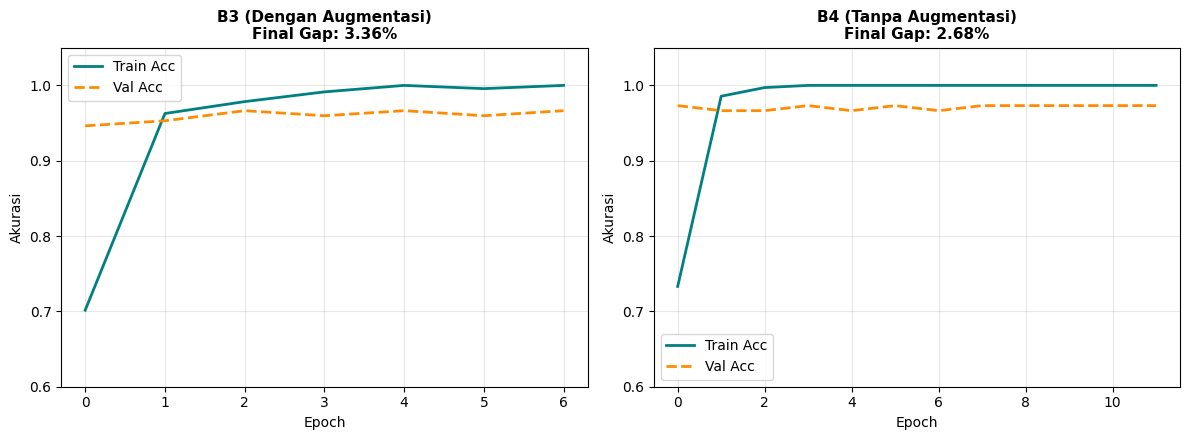

In [12]:
# 1. Generalization Gap Akhir (Train Acc - Val Acc)
gap_b1 = (hist_b1['train_acc'][-1] - hist_b1['val_acc'][-1]) * 100
gap_b2 = (hist_b2['train_acc'][-1] - hist_b2['val_acc'][-1]) * 100
gap_b3 = (hist_b3['train_acc'][-1] - hist_b3['val_acc'][-1]) * 100
gap_b4 = (hist_b4['train_acc'][-1] - hist_b4['val_acc'][-1]) * 100

print("=" * 70)
print("RINGKASAN METRIK UNTUK PEMBAHASAN C2")
print("=" * 70)
print(f"1. Disparitas Akurasi Test  : B1 = {acc_b1*100:.2f}%  vs  B2 = {acc_b2*100:.2f}% (Lonjakan: +{(acc_b2-acc_b1)*100:.2f}%)")
print(f"2. Kecepatan Konvergensi    : B2 = {epochs_b2} epoch  vs  B3 = {epochs_b3} epoch (Lebih cepat {epochs_b2 - epochs_b3} epoch)")
print(f"3. Generalization Gap (Overfitting Level):")
print(f"   - B3 (Dengan Augmentasi) : Train {hist_b3['train_acc'][-1]*100:.2f}% | Val {hist_b3['val_acc'][-1]*100:.2f}% | Gap = {gap_b3:.2f}%")
print(f"   - B4 (Tanpa Augmentasi)  : Train {hist_b4['train_acc'][-1]*100:.2f}% | Val {hist_b4['val_acc'][-1]*100:.2f}% | Gap = {gap_b4:.2f}%")
print("=" * 70)

# 2. Visualisasi Kurva Akurasi Train vs Val (Gap Overfitting B3 vs B4)
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(hist_b3['train_acc'], label='Train Acc', color='teal', lw=2)
plt.plot(hist_b3['val_acc'], label='Val Acc', color='darkorange', linestyle='--', lw=2)
plt.title(f'B3 (Dengan Augmentasi)\nFinal Gap: {gap_b3:.2f}%', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.ylim(0.6, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_b4['train_acc'], label='Train Acc', color='teal', lw=2)
plt.plot(hist_b4['val_acc'], label='Val Acc', color='darkorange', linestyle='--', lw=2)
plt.title(f'B4 (Tanpa Augmentasi)\nFinal Gap: {gap_b4:.2f}%', fontsize=11, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.ylim(0.6, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("accuracy_gap_c2_analysis.png", dpi=300)
plt.show()

# 12. Failure Analysis


Total sampel salah ditemukan: 1
Total sampel yang dianalisis: 6


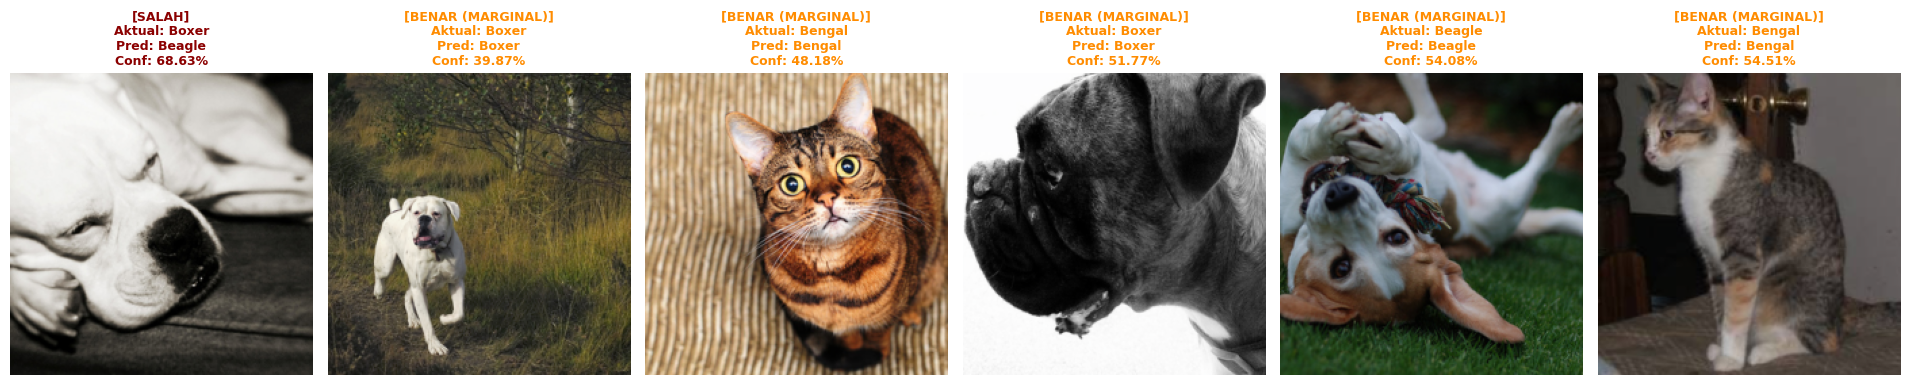


TABEL FAILURE ANALISYS):
------------------------------------------------------------------------------------------
Sampel #1 (Misklasifikasi):
  - Label Aktual       : Boxer
  - Prediksi Model     : Beagle (Keyakinan: 68.63%)
------------------------------------------------------------------------------------------
Sampel #2 (Ketidakpastian Tinggi):
  - Label Aktual       : Boxer
  - Prediksi Model     : Boxer (Keyakinan: 39.87%)
------------------------------------------------------------------------------------------
Sampel #3 (Ketidakpastian Tinggi):
  - Label Aktual       : Bengal
  - Prediksi Model     : Bengal (Keyakinan: 48.18%)
------------------------------------------------------------------------------------------
Sampel #4 (Ketidakpastian Tinggi):
  - Label Aktual       : Boxer
  - Prediksi Model     : Boxer (Keyakinan: 51.77%)
------------------------------------------------------------------------------------------
Sampel #5 (Ketidakpastian Tinggi):
  - Label Aktual    

In [13]:
best_model = model_b4
best_model.eval()

misclassified_items = []
marginal_items = []

mean = np.array(weights.transforms().mean)
std = np.array(weights.transforms().std)

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs_dev = inputs.to(device)
        outputs = best_model(inputs_dev)
        probs = torch.softmax(outputs, dim=1)
        confidences, preds = torch.max(probs, 1)

        for i in range(inputs.size(0)):
            img = inputs[i].cpu().permute(1, 2, 0).numpy()
            img = np.clip(std * img + mean, 0, 1)

            true_label = class_names[labels[i]]
            pred_label = class_names[preds[i]]
            conf = confidences[i].item()

            item_info = {
                'img': img,
                'true_label': true_label,
                'pred_label': pred_label,
                'conf': conf,
                'is_error': preds[i] != labels[i]
            }

            if preds[i] != labels[i]:
                misclassified_items.append(item_info)
            else:
                marginal_items.append(item_info)

marginal_items = sorted(marginal_items, key=lambda x: x['conf'])
total_samples = misclassified_items + marginal_items[:max(0, 6 - len(misclassified_items))]
samples_to_plot = total_samples[:min(8, len(total_samples))]

print(f"Total sampel salah ditemukan: {len(misclassified_items)}")
print(f"Total sampel yang dianalisis: {len(samples_to_plot)}")

n_samples = len(samples_to_plot)
plt.figure(figsize=(3.2 * n_samples, 4.2))

for idx, item in enumerate(samples_to_plot):
    plt.subplot(1, n_samples, idx + 1)
    plt.imshow(item['img'])
    status = "SALAH" if item['is_error'] else "BENAR (MARGINAL)"
    title_color = "darkred" if item['is_error'] else "darkorange"

    plt.title(
        f"[{status}]\nAktual: {item['true_label']}\nPred: {item['pred_label']}\nConf: {item['conf']:.2%}",
        fontsize=9,
        color=title_color,
        fontweight='bold'
    )
    plt.axis('off')

plt.tight_layout()
plt.savefig("c3_failure_analysis.png", dpi=300)
plt.show()

print("\nTABEL FAILURE ANALISYS):")
print("-" * 90)
for idx, item in enumerate(samples_to_plot, 1):
    tipe = "Misklasifikasi" if item['is_error'] else "Ketidakpastian Tinggi"
    print(f"Sampel #{idx} ({tipe}):")
    print(f"  - Label Aktual       : {item['true_label']}")
    print(f"  - Prediksi Model     : {item['pred_label']} (Keyakinan: {item['conf']:.2%})")
    print("-" * 90)